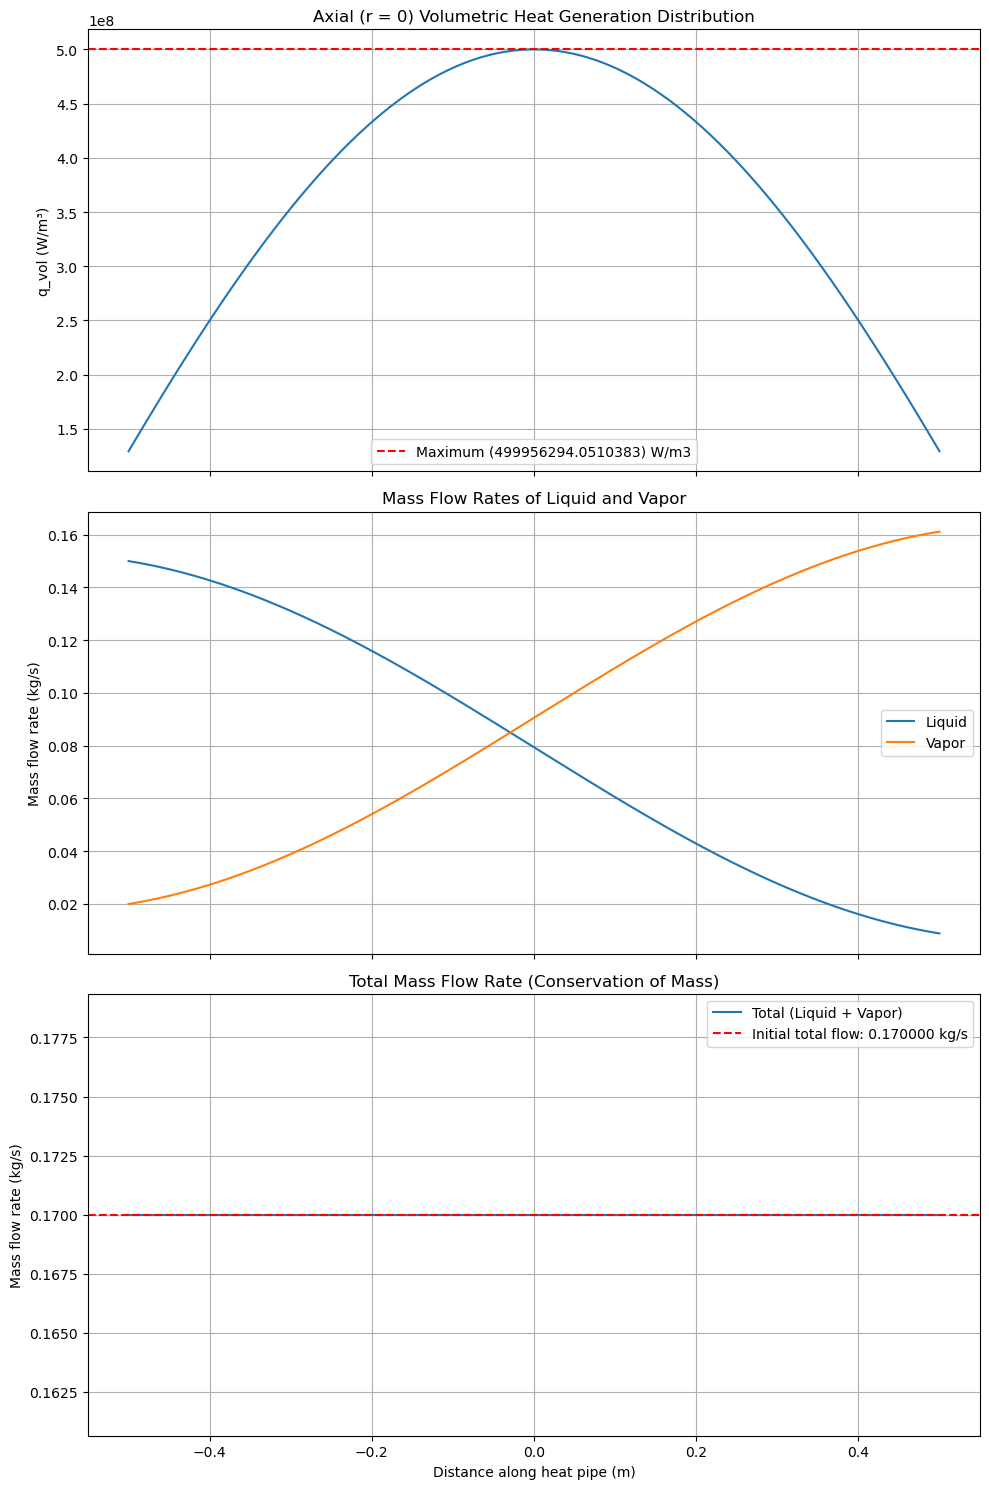

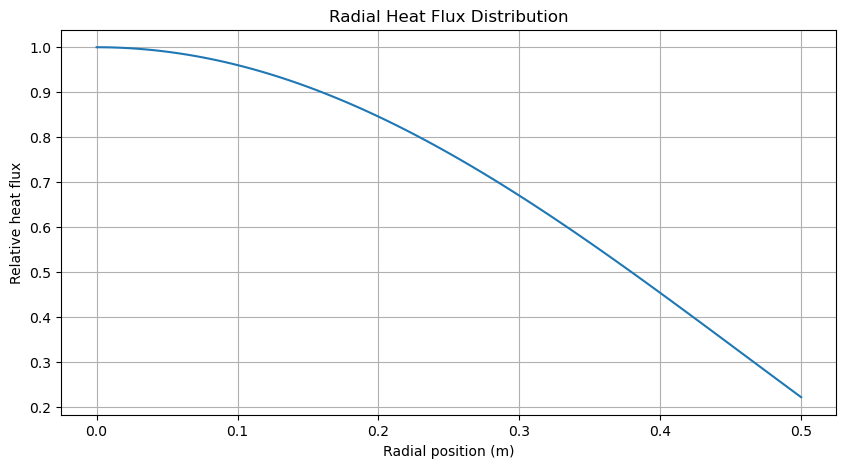


Radial position of the heat pipe: 0.00 m
Relative heat flux at this position: 1.0000
Initial total mass flow rate: 0.170000 kg/s
Final total mass flow rate: 0.170000 kg/s
Difference: 0.000000000 kg/s

Total evaporation along the heat pipe: 0.141174 kg/s
Final liquid mass flow rate: 0.008826 kg/s
Final vapor mass flow rate: 0.161174 kg/s
Average evaporation flux: 94.12 kg/(m^2·s)


In [1]:
import numpy as np
from scipy import integrate, special
import matplotlib.pyplot as plt
import pandas as pd
from scipy.interpolate import interp1d

def create_default_q_vol(H, dz, r, R, dr, num_points=100, q_max=500e6):
    """
    Create a default heat flux distribution using a cosine function with buffer zones,
    adjusted by the Bessel function for radial position.
    """
    z = np.linspace(-H/2, H/2, num_points)
    q_axial = q_max * np.cos(np.pi * z / (H + 2*dz))
    q_radial = special.j0(2.405 * r / (R + dr))
    q = q_axial * q_radial
    return pd.DataFrame({'z': z, 'q_vol': q})

def load_q_vol(filename=None, H=1.0, d=0.1, r=0, R=1, dr=0.1, num_points=100):
    """
    Load q_vol data from a CSV file or create a default distribution.
    Returns an interpolation function.
    """
    if filename:
        try:
            data = pd.read_csv(filename)
        except FileNotFoundError:
            print(f"File {filename} not found. Using default distribution.")
            data = create_default_q_vol(H, d, r, R, dr, num_points)
    else:
        data = create_default_q_vol(H, d, r, R, dr, num_points)
    
    return interp1d(data['z'], data['q_vol'], kind='linear', fill_value='extrapolate'), data

def dm_dz(z, q_func, fuel_area, latent_heat):
    """
    Differential equation for mass flow rate.
    """
    return fuel_area * q_func(z) / latent_heat

def calculate_mass_flow(z_start, z_end, q_func, fuel_area, latent_heat, num_points=1000):
    """
    Calculate the mass flow rate from z_start to z_end using Simpson's rule.
    """
    z = np.linspace(z_start, z_end, num_points)
    integrand = dm_dz(z, q_func, fuel_area, latent_heat)
    return integrate.simpson(y=integrand, x=z)

# Parameters
filename = None  # Set to None to use default distribution
Height = 1.0  # m, length of the heat pipe
dz = 0.1  # m, buffer zone length
r = 0.0  # m, radial position of the heat pipe (change this to simulate different positions)
Radius = 0.5  # m, radius of the reactor
dr = 0.1  # m, radial buffer zone
fuel_area = 15e-4  # m^2, converted from 15 cm^2
latent_heat = 3920000  # J/kg, latent heat of vaporization
initial_liquid_flow = 0.15  # kg/s
initial_vapor_flow = 0.02  # kg/s

# Load q_vol data or create default
q_func, data = load_q_vol(filename, Height, dz, r, Radius, dr)

# Create array of z values
num_points = 1000  # Increased number of points for better resolution
z_values = np.linspace(-Height/2, Height/2, num_points)

# Calculate evaporation rate at each point
evaporation_rates = [dm_dz(z, q_func, fuel_area, latent_heat) for z in z_values]

# Calculate cumulative evaporation for each z value
cumulative_evaporation = [calculate_mass_flow(-Height/2, z, q_func, fuel_area, latent_heat) for z in z_values]

# Calculate mass flow rates with initial values
liquid_mass_flow = [initial_liquid_flow - evap for evap in cumulative_evaporation]
vapor_mass_flow = [initial_vapor_flow + evap for evap in cumulative_evaporation]

# Calculate total mass flow (should be constant if mass is conserved)
total_mass_flow = [liquid + vapor for liquid, vapor in zip(liquid_mass_flow, vapor_mass_flow)]

# Plot the results
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 15), sharex=True)

# Plot heat flux distribution
ax1.plot(data['z'], data['q_vol'])
ax1.set_title(f'Axial (r = 0) Volumetric Heat Generation Distribution')
ax1.set_ylabel('q_vol (W/m³)')
ax1.axhline(np.max(data['q_vol']), label=f'Maximum ({np.max(data['q_vol'])}) W/m3', color='red', linestyle='--')
ax1.legend()
ax1.grid(True)

# Plot combined liquid and vapor mass flow rates
ax2.plot(z_values, liquid_mass_flow, label='Liquid')
ax2.plot(z_values, vapor_mass_flow, label='Vapor')
ax2.set_title('Mass Flow Rates of Liquid and Vapor')
ax2.set_ylabel('Mass flow rate (kg/s)')
ax2.grid(True)
ax2.legend()

# Plot total mass flow rate to show conservation of mass
ax3.plot(z_values, total_mass_flow, label='Total (Liquid + Vapor)')
ax3.set_title('Total Mass Flow Rate (Conservation of Mass)')
ax3.set_xlabel('Distance along heat pipe (m)')
ax3.set_ylabel('Mass flow rate (kg/s)')
ax3.grid(True)
ax3.legend()

# Add a horizontal line at the initial total mass flow rate
initial_total_flow = initial_liquid_flow + initial_vapor_flow
ax3.axhline(y=initial_total_flow, color='r', linestyle='--', 
            label=f'Initial total flow: {initial_total_flow:.6f} kg/s')
ax3.legend()

plt.tight_layout()
plt.show()

# Additional plot to show radial heat flux distribution
fig, ax = plt.subplots(figsize=(10, 5))
r_values = np.linspace(0, Radius, 100)
q_radial = [special.j0(2.405 * r / (Radius + dr)) for r in r_values]
ax.plot(r_values, q_radial)
ax.set_title('Radial Heat Flux Distribution')
ax.set_xlabel('Radial position (m)')
ax.set_ylabel('Relative heat flux')
ax.grid(True)
plt.show()

# Print radial position and its effect
print(f"\nRadial position of the heat pipe: {r:.2f} m")
print(f"Relative heat flux at this position: {special.j0(2.405 * r / (Radius + dr)):.4f}")

# Calculate and print results
total_evaporation = cumulative_evaporation[-1]
final_liquid_flow = liquid_mass_flow[-1]
final_vapor_flow = vapor_mass_flow[-1]
final_total_flow = total_mass_flow[-1]
average_mass_flux = total_evaporation / fuel_area

print(f"Initial total mass flow rate: {initial_total_flow:.6f} kg/s")
print(f"Final total mass flow rate: {final_total_flow:.6f} kg/s")
print(f"Difference: {final_total_flow - initial_total_flow:.9f} kg/s")
print(f"\nTotal evaporation along the heat pipe: {total_evaporation:.6f} kg/s")
print(f"Final liquid mass flow rate: {final_liquid_flow:.6f} kg/s")
print(f"Final vapor mass flow rate: {final_vapor_flow:.6f} kg/s")
print(f"Average evaporation flux: {average_mass_flux:.2f} kg/(m^2·s)")


Exact value: 0.3333333333333333
Quad method result: 0.33333333333333337, error: 5.551115123125783e-17
Simpson's rule result: 0.33333333333333337, error: 5.551115123125783e-17

Time for 1000 integrations:
Quad method: 0.010003 seconds
Simpson's rule: 0.134629 seconds
[    10     16     26     42     70    112    184    298    484    784
   1274   2070   3360   5456   8858  14384  23358  37926  61584 100000]


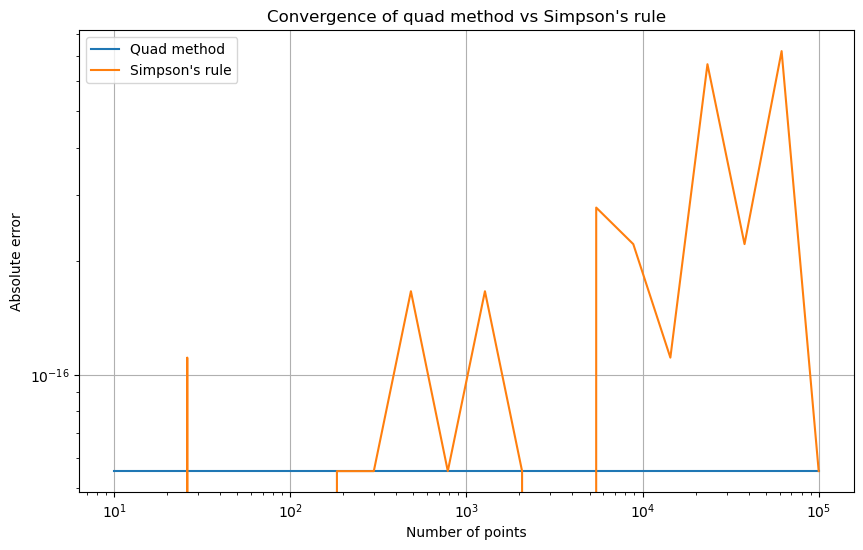

In [18]:
import numpy as np
from scipy import integrate
import time
import matplotlib.pyplot as plt

def f(x):
    return x**2

def simpson_rule(f, a, b, n):
    """Simpson's rule implementation"""
    if n % 2 != 0:
        raise ValueError("n must be even")
    
    h = (b - a) / n
    x = np.linspace(a, b, n+1)
    y = f(x)
    
    return h/3 * (y[0] + 4*sum(y[1:-1:2]) + 2*sum(y[2:-1:2]) + y[-1])

# Define integration limits
a, b = 0, 1

# Exact value of the integral of x^2 from 0 to 1
exact_value = 1/3

# Compare accuracy
quad_result, quad_error = integrate.quad(f, a, b)
simpson_result = simpson_rule(f, a, b, 1000)  # Using 1000 intervals

print(f"Exact value: {exact_value}")
print(f"Quad method result: {quad_result}, error: {abs(quad_result - exact_value)}")
print(f"Simpson's rule result: {simpson_result}, error: {abs(simpson_result - exact_value)}")

# Compare speed
n_tests = 1000

start_time = time.time()
for _ in range(n_tests):
    integrate.quad(f, a, b)
quad_time = time.time() - start_time

start_time = time.time()
for _ in range(n_tests):
    simpson_rule(f, a, b, 1000)
simpson_time = time.time() - start_time

print(f"\nTime for {n_tests} integrations:")
print(f"Quad method: {quad_time:.6f} seconds")
print(f"Simpson's rule: {simpson_time:.6f} seconds")

# Compare convergence
n_points = np.unique(np.ceil(np.logspace(1, 5, 20, dtype=int) / 2).astype(int) * 2)
print(n_points)
quad_errors = []
simpson_errors = []

for n in n_points:
    quad_result, _ = integrate.quad(f, a, b)
    simpson_result = simpson_rule(f, a, b, n)
    
    quad_errors.append(abs(quad_result - exact_value))
    simpson_errors.append(abs(simpson_result - exact_value))

plt.figure(figsize=(10, 6))
plt.loglog(n_points, quad_errors, label='Quad method')
plt.loglog(n_points, simpson_errors, label="Simpson's rule")
plt.xlabel('Number of points')
plt.ylabel('Absolute error')
plt.title("Convergence of quad method vs Simpson's rule")
plt.legend()
plt.grid(True)
plt.show()

$\frac{1}{3}$